# 1 · Attribution: which squares made the network choose that move?

**Interpretability notebook 1.** The four training notebooks built a chess
network. This series opens it up. The series climbs one ladder:

| | question | notebook |
|---|---|---|
| **1** | **what does the network look at?** | **attribution** (this one) |
| 2 | what does it know? | probing |
| 3 | does it use what it knows? | causal interventions |
| 4 | can we change its mind? | steering |
| 5–6 | how does it compute? | mechanistic interpretability |

An **attribution method** takes one input and one output and hands back a score
for every input feature: *how much did this feature contribute to that output?*
For a chess network the input features are pieces on squares, so every
attribution is a heatmap on a chessboard, which makes it easy to read.

Easy to read is not the same as correct. Attribution maps look convincing even
when they are wrong. So alongside each method this notebook asks the question
every interpretability result needs: **how would we know if this explanation
were wrong?**

**What we explain.** The *raw network* from `engine.pt` (the AlphaZero-trained
6×64 ResNet), with **no search**. The bot you play in the browser wraps this
network in 200 simulations of MCTS. Here we look at the network on its own: one
forward pass, one board in, a move distribution and a win/draw/loss estimate out.

**Plan**
1. The model and four test positions
2. What exactly are we explaining?
3. Gradients (saliency)
4. Gradient × input
5. Integrated gradients
6. The baseline problem
7. Occlusion: take a piece off the board
8. The four methods side by side
9. Explaining a blunder (contrastive attribution)
10. Are the explanations faithful? Deletion curves
11. Sanity check: does the explanation depend on the model at all?
12. Summary

In [1]:
import sys, time
from pathlib import Path
import numpy as np, chess, torch
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "interp" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "train"))
from chesslib import load_checkpoint
from chesslib.data import load_games
from chesslib.interp import (board_tensor, square_map, group_totals, value_target,
                             policy_target, Target, top_moves, removable_squares, remove_pieces,
                             kings_only_baseline, randomized_copy, randomization_stages,
                             recalibrate_batchnorm, sample_positions, rank_corr, plot_board,
                             show_boards)

torch.manual_seed(0); np.random.seed(0)
torch.set_num_threads(8)
CKPT = ROOT / "train" / "checkpoints"
plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False})

## 1 · The model and four test positions

We load two networks with the same architecture:

* **`engine`**: the final AlphaZero-style network. This is the one we explain.
* **`random`**: the same architecture with freshly initialised weights. It is
  the **control** for section 11: an explanation that looks the same for a
  network that learned nothing is not explaining what was learned.

Then we pick four positions where a chess player can say *why* the right move
is right. Each one gives us an expectation to check the maps against.

In [2]:
engine = load_checkpoint(CKPT / "engine.pt")

# a fixed sample of real positions from ab2-vs-ab2 games (the SFT training distribution);
# used for every dataset-level experiment below
games = load_games(players=["ab2"])
positions = sample_positions(games, 300, seed=0)
X = torch.cat([board_tensor(b) for b in positions])

random_net = recalibrate_batchnorm(randomized_copy(engine, "all"), X)
print(f"{len(positions)} sample positions from {len(games):,} ab2 games")

300 sample positions from 6,000 ab2 games


back-rank mate  White to move | expected: Rd8# — Black's own pawns on f7/g7/h7 box the king in
                network: Rd8# 73%, Rd7 7%, Kf1 3% | W/D/L 0.98/0.02/0.01
knight fork     White to move | expected: Nc7+ forks the king on e8 and the rook on a8
                network: Nc7+ 91%, O-O 3%, O-O-O 1% | W/D/L 0.31/0.46/0.24
hanging queen   White to move | expected: Nxh4 wins the undefended queen
                network: Nxh4 9%, Nxe5 5%, d4 5% | W/D/L 0.45/0.10/0.44
mate threat     Black to move | expected: Black must stop Qxf7# (queen h5 + bishop c4), e.g. g6 or Qe7
                network: Nf6 16%, d5 6%, g6 6% | W/D/L 0.51/0.08/0.41


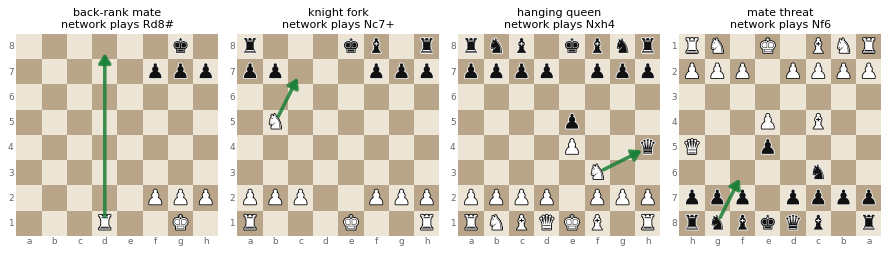

In [3]:
SHOWCASE = {
    "back-rank mate": chess.Board("6k1/5ppp/8/8/8/8/5PPP/3R2K1 w - - 0 1"),
    "knight fork":    chess.Board("r3kb1r/pp3ppp/8/1N6/8/8/PPP2PPP/R3K2R w KQkq - 0 1"),
    "hanging queen":  chess.Board("rnb1kbnr/pppp1ppp/8/4p3/4P2q/5N2/PPPP1PPP/RNBQKB1R w KQkq - 2 3"),
    "mate threat":    chess.Board("r1bqkbnr/pppp1ppp/2n5/4p2Q/2B1P3/8/PPPP1PPP/RNB1K1NR b KQkq - 3 3"),
}
EXPECT = {
    "back-rank mate": "Rd8# — Black's own pawns on f7/g7/h7 box the king in",
    "knight fork":    "Nc7+ forks the king on e8 and the rook on a8",
    "hanging queen":  "Nxh4 wins the undefended queen",
    "mate threat":    "Black must stop Qxf7# (queen h5 + bishop c4), e.g. g6 or Qe7",
}
panels = []
for name, b in SHOWCASE.items():
    moves, wdl = top_moves(engine, b, 3)
    print(f"{name:15s} {'White' if b.turn else 'Black'} to move | expected: {EXPECT[name]}")
    print(f"{'':15s} network: " + ", ".join(f"{b.san(m)} {p:.0%}" for m, p in moves)
          + f" | W/D/L {wdl[0]:.2f}/{wdl[1]:.2f}/{wdl[2]:.2f}")
    panels.append(dict(board=b, move=moves[0][0], title=f"{name}\nnetwork plays {b.san(moves[0][0])}"))
show_boards(panels, size=2.8);

The network plays the expected move in the first three positions. It is far more
confident about the mate and the fork than about winning the queen.

In the fourth it **blunders**: it prefers ...Nf6, which allows Qxf7#. Search
doesn't rescue it either. The full engine (this network plus 200 simulations of
MCTS) also plays ...Nf6, as we check in section 9. Explaining a *mistake* is one of the most useful
things attribution can do, and we come back to it in section 9.

Boards are drawn from the side to move's point of view, the same way the network
sees them.

## 2 · What exactly are we explaining?

An attribution explains **one scalar output**, so we have to choose one. The
network has two heads:

* **value**: $v(s) = P(\text{win}) - P(\text{loss}) \in [-1, 1]$, for the side to move.
  *"How good is this position for me?"*
* **policy**: $\log \pi(a \mid s)$, the log-probability of move $a$ among the
  legal moves. *"Why this move?"*

We explain the **log-probability**, not the raw logit. Only differences between
logits matter: adding 5 to every logit changes nothing the network does. A
log-probability is a logit *compared with its rivals*, so "why this move" really
means "why this move rather than the others."

**From planes to squares.** The input is 21 planes of 8×8 (from
`chesslib/encoding.py`). Planes 0–11 say *which piece is on which square*, and
an attribution on those planes belongs to a square. The other planes are
**global**: castling rights, the 50-move clock, repetitions, and a constant
plane of ones. Each copies one number to all 64 squares, so a per-square view of
them means nothing. We sum the piece planes to get one number per square, and
report the global planes separately as totals.

Every target below is an ordinary function `f(x)` of a batch of input planes,
so every method can be written in terms of it.

In [4]:
b = SHOWCASE["back-rank mate"]
x = board_tensor(b)
f_val = value_target(engine)
f_pol = policy_target(engine, b, chess.Move.from_uci("d1d8"))
print(f"value  v(s)         = {f_val(x).item():+.3f}")
print(f"policy {f_pol.name:12s} = {f_pol(x).item():+.3f}  (prob {f_pol(x).exp().item():.0%})")

value  v(s)         = +0.969
policy log π(Rd8#)  = -0.308  (prob 73%)


## 3 · Gradients ("saliency")

The oldest method: compute $\partial f / \partial x$ and call large gradients
important. One backward pass gives a number for **every plane on every square**,
including empty squares.

That should make us suspicious. The gradient at an *empty* square on the
"their queen" plane answers this question: **if a tiny amount of an enemy queen
appeared on this square, how would the output change?** That is a real and
sometimes useful question. But it is a *hypothetical* about a different board,
not an account of the board in front of us. Our inputs are also 0/1. Nobody can
place 0.01 of a queen, so we are asking about inputs that never occur.

Below, for the back-rank position, are four of the 21 gradient planes for the
**value**.

mean |∂v/∂x| here (v = +0.97): 0.027
  sample positions with |v| < 0.3: 0.139
  sample positions with |v| > 0.9: 0.013


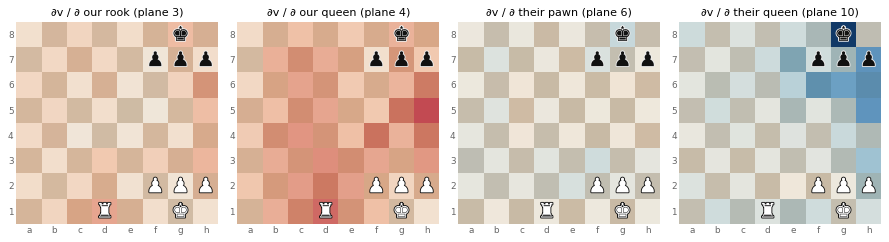

In [5]:
def gradient(target, x):
    # ∂f/∂x for every plane and square: shape (21, 8, 8)
    x = x.clone().requires_grad_(True)
    g, = torch.autograd.grad(target(x).sum(), x)
    return g[0].detach()

from chesslib.interp import to_real_squares
g = gradient(f_val, x)
planes = {"our rook (plane 3)": 3, "our queen (plane 4)": 4,
          "their pawn (plane 6)": 6, "their queen (plane 10)": 10}
show_boards([dict(board=b, values=to_real_squares(g[p], b.turn), title=f"∂v / ∂ {name}")
             for name, p in planes.items()], size=2.8, shared_scale=True);

# how big are value gradients here, compared with typical positions?
def mean_abs_grad(board):
    return gradient(value_target(engine), board_tensor(board)).abs().mean().item()
with torch.no_grad():
    v_all = value_target(engine)(X).numpy()
grads = np.array([mean_abs_grad(p) for p in positions])
print(f"mean |∂v/∂x| here (v = {f_val(x).item():+.2f}): {mean_abs_grad(b):.3f}")
print(f"  sample positions with |v| < 0.3: {grads[np.abs(v_all) < 0.3].mean():.3f}")
print(f"  sample positions with |v| > 0.9: {grads[np.abs(v_all) > 0.9].mean():.3f}")

Read the right-hand map as "where would an extra enemy queen hurt me most?" The
blue is concentrated in Black's kingside corner (f6–h6, h5, h7), where a black
queen would help defend. The single darkest square is **g8, where the black
king already stands**. A queen can't share a square with a king, so the
gradient is happily answering a question about an impossible board. The "our
queen" map is the reverse and much flatter: an extra White queen helps almost
anywhere. The pawn map is nearly blank.

All of these numbers are small, and the printout says why. The value is already
+0.97, and the gradient here is about five times smaller than in balanced positions. That is **saturation**. Once the network is sure,
small changes to the input barely move the output, including on the pieces
that made it sure.

So these are maps of the network's *sensitivities*. They don't explain *this*
position. To get an explanation, we have to account for what is actually on the
board.

## 4 · Gradient × input

Multiply the gradient by the input, elementwise: $a_i = x_i \,\partial f/\partial x_i$.
On binary piece planes this keeps the gradient only where a piece *is*, so every
attribution belongs to a real piece.

It is a **first-order Taylor expansion**. If $f$ were linear,
$f(x) - f(0) = \sum_i x_i\,\partial f/\partial x_i$ exactly, and the attributions
would add up to the output. A 6-block ResNet is not linear. Removing a piece is
a jump from 1 to 0, not an infinitesimal nudge. So the scores need not add up to
anything. We check how far off they are.

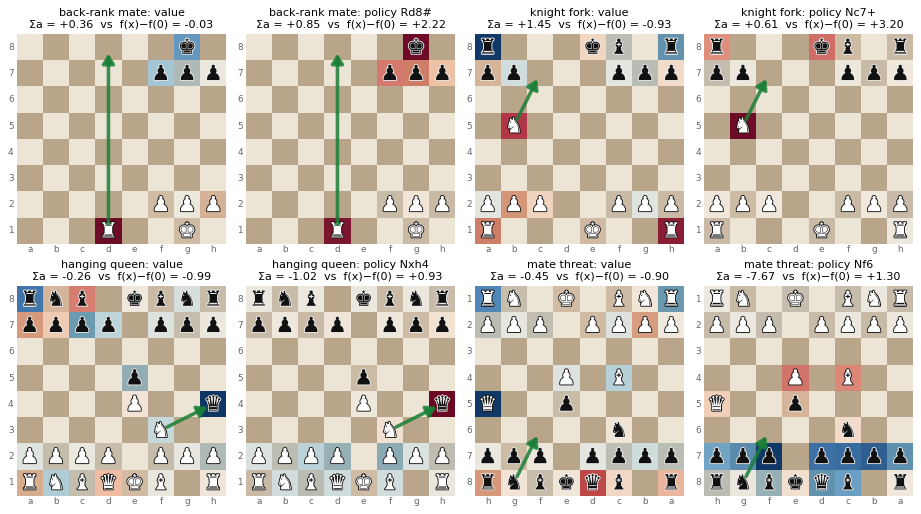

In [6]:
def grad_x_input(target, x):
    return (gradient(target, x) * x[0])

panels = []
for name, b in SHOWCASE.items():
    move = top_moves(engine, b, 1)[0][0][0]
    xb = board_tensor(b)
    for label, t in [("value", value_target(engine)), (f"policy {b.san(move)}", policy_target(engine, b, move))]:
        a = grad_x_input(t, xb)
        with torch.no_grad():
            gap = t(xb).item() - t(torch.zeros_like(xb)).item()
        panels.append(dict(board=b, values=square_map(a, b.turn), move=move,
                           title=f"{name}: {label}\nΣa = {a.sum():+.2f}  vs  f(x)−f(0) = {gap:+.2f}"))
show_boards(panels, ncols=4, size=2.9);

Red means the piece pushes the output **up** (towards a win, or towards playing
the move). Blue means it pushes the output down.

Some of the maps already make sense. For the fork, the knight lights up for the
policy. For the back-rank mate, the rook, the black king and the pawns that box it in do. But the titles
show the totals are far from $f(x) - f(0)$, the change between an empty board
and this board. We have no idea how much of the output the map accounts for.

## 5 · Integrated gradients

Integrated gradients (IG; Sundararajan et al. 2017) fixes the bookkeeping. Pick
a **baseline** input $x'$ that means "no information." Walk in a straight line
from $x'$ to $x$, add up the gradient along the way, and multiply by the
distance travelled:

$$\mathrm{IG}_i(x) = (x_i - x'_i)\int_0^1 \frac{\partial f\big(x' + \alpha(x - x')\big)}{\partial x_i}\,d\alpha$$

By the fundamental theorem of calculus (for line integrals), the attributions
now add up exactly:

$$\textstyle\sum_i \mathrm{IG}_i(x) = f(x) - f(x') \qquad\text{(completeness)}$$

Every bit of the output change is assigned to some input feature, and none is
created or lost. In code, the integral is a Riemann sum over `steps` points on
the path, all evaluated in one batch.

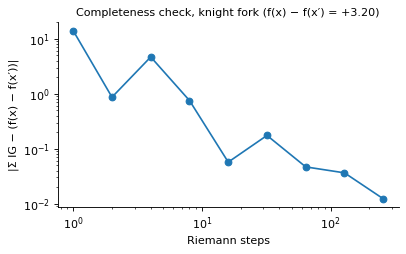

In [7]:
def integrated_gradients(target, x, baseline, steps=64):
    alphas = (torch.arange(steps) + 0.5) / steps                  # midpoint rule on [0, 1]
    path = baseline + alphas.view(-1, 1, 1, 1) * (x - baseline)    # (steps, 21, 8, 8)
    path.requires_grad_(True)
    grads, = torch.autograd.grad(target(path).sum(), path)
    return ((x - baseline) * grads.mean(0, keepdim=True))[0].detach()

b = SHOWCASE["knight fork"]; xb = board_tensor(b)
t = policy_target(engine, b, chess.Move.from_uci("b5c7"))
base = torch.zeros_like(xb)
with torch.no_grad():
    exact = (t(xb) - t(base)).item()
steps = [1, 2, 4, 8, 16, 32, 64, 128, 256]
errors = [abs(integrated_gradients(t, xb, base, s).sum().item() - exact) for s in steps]

fig, ax = plt.subplots(figsize=(5.5, 3))
ax.loglog(steps, errors, "o-")
ax.set_xlabel("Riemann steps"); ax.set_ylabel("|Σ IG − (f(x) − f(x′))|")
ax.set_title(f"Completeness check, knight fork (f(x) − f(x′) = {exact:+.2f})", fontsize=10)
plt.show()

The completeness error shrinks as the number of steps grows (not smoothly, but
by about three orders of magnitude). At 64 steps it is under 2% of the total. Checking
it is cheap and worth doing every time you run IG, because a large gap means
too few steps. We use 64 from here on.

**A caveat.** The straight-line path goes through inputs like "0.5 of a knight
on b5 and 0.5 of a rook on a8." Those are not chess positions, and the network
never saw anything like them in training. IG's guarantee only says the
attributions *add up*. It says nothing about whether the network acts sensibly
along the path.

## 6 · The baseline problem

Completeness says the attributions explain $f(x) - f(x')$. So **the baseline
defines the question.** "Why this output?" really means "why this output rather
than the output for $x'$?" Two natural choices:

* **All zeros.** No pieces, and also no castling rights and no constant plane.
  This input is far from anything the network has seen. Even the "board edge"
  plane disappears.
* **Kings only.** Remove every piece except the two kings, and keep the global
  planes as they are. This is close to a real position (only the castling planes no longer match
the pieces), and it asks a cleaner
  question: *what do the pieces contribute?*

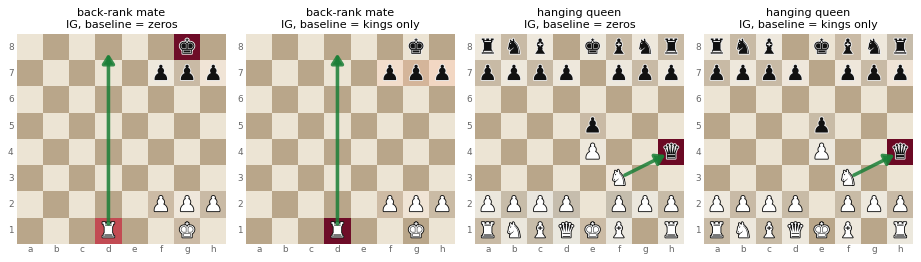

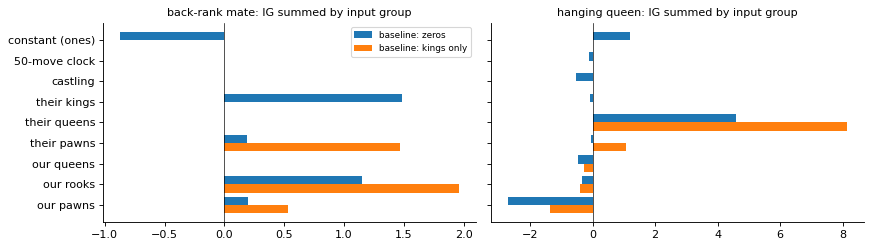

In [8]:
panels, totals = [], {}
for name in ["back-rank mate", "hanging queen"]:
    b = SHOWCASE[name]; xb = board_tensor(b)
    move = top_moves(engine, b, 1)[0][0][0]
    t = policy_target(engine, b, move)
    for bl_name, bl in [("zeros", torch.zeros_like(xb)), ("kings only", kings_only_baseline(xb))]:
        a = integrated_gradients(t, xb, bl)
        totals[(name, bl_name)] = group_totals(a)
        panels.append(dict(board=b, values=square_map(a, b.turn), move=move,
                           title=f"{name}\nIG, baseline = {bl_name}"))
show_boards(panels, ncols=4, size=2.9);

groups = ["our pawns", "our rooks", "our queens", "their pawns", "their queens", "their kings",
          "castling", "50-move clock", "constant (ones)"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, name in zip(axes, ["back-rank mate", "hanging queen"]):
    for k, bl_name in enumerate(["zeros", "kings only"]):
        vals = [totals[(name, bl_name)][g] for g in groups]
        ax.barh(np.arange(len(groups)) + 0.2 * (1 - 2 * k), vals, height=0.4, label=f"baseline: {bl_name}")
    ax.axvline(0, color="k", lw=0.6); ax.set_title(f"{name}: IG summed by input group", fontsize=10)
    ax.set_yticks(range(len(groups))); ax.set_yticklabels(groups)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

The baseline changes **which pieces get credit**.

* **Back-rank mate.** With the zeros baseline, almost everything goes to the
  black king (+1.5) and the rook (+1.2). With the kings-only baseline, kings
  are part of the baseline, so they get no credit by construction. That credit
  moves to the rook and to the **f7/g7/h7 pawns** ("their pawns" in the bar
  chart goes from 0.2 to 1.5). Those pawns are the actual reason Rd8 is mate.
* **Hanging queen.** Both baselines put nearly everything on the black queen,
  so here the choice changes the size of the numbers, not the story.
* **Global planes.** With the zeros baseline, the **constant plane** gets a
  large share in both positions (−0.9 and +1.2), and so do the **castling**
  planes in the hanging-queen position. That doesn't mean the network "uses the
  board-edge plane to find Rd8#." Those planes are part of what separates a
  real board from the impossible all-zeros input, and IG has to credit the
  difference to something. The kings-only baseline holds them fixed, so they
  get exactly zero.

**Rule of thumb: a baseline is not a neutral default. It is half of your
question.** From here on we use the kings-only baseline.

## 7 · Occlusion: take a piece off the board

Gradient methods judge a piece by how the output responds to *infinitesimal*
changes. Chess has a natural *discrete* experiment instead. **Remove the piece
and see what happens:**

$$\text{occlusion}(p) = f(\text{board}) - f(\text{board without } p)$$

A positive score means the piece was pushing the output up. This is a real
counterfactual: the board without the piece is a legal chess position. No
half-knights, no gradients, no baseline to choose. It costs one forward pass
per piece.

Some pieces can't be removed. **Kings** can't. The **moving piece** can't, for a
policy target: without it the move doesn't exist. And a removal that leaves the
side *not* to move in check produces an impossible position, so we skip that
too. These squares are **hatched** on the maps.

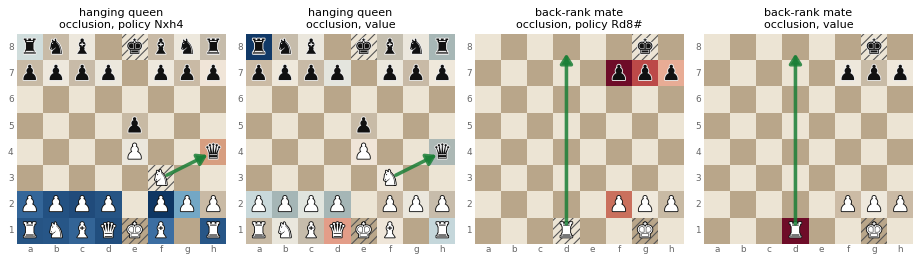

In [9]:
@torch.no_grad()
def occlusion(target, board):
    out = np.full(64, np.nan)
    full = target(board_tensor(board)).item()
    for sq in removable_squares(board):
        b2 = remove_pieces(board, [sq])
        t2 = target.for_board(b2)      # the same question asked of the new board
        if t2 is not None:             # None: the move is no longer legal
            out[sq] = full - t2(board_tensor(b2)).item()
    return out

def hatched(board, values):
    return [sq for sq in board.piece_map() if np.isnan(values[sq])]

panels = []
for name in ["hanging queen", "back-rank mate"]:
    b = SHOWCASE[name]; move = top_moves(engine, b, 1)[0][0][0]
    for label, t in [(f"policy {b.san(move)}", policy_target(engine, b, move)),
                     ("value", value_target(engine))]:
        o = occlusion(t, b)
        panels.append(dict(board=b, values=o, move=move, hatch=hatched(b, o),
                           title=f"{name}\nocclusion, {label}"))
show_boards(panels, ncols=4, size=2.9);

Two of these maps look strange.

* **Hanging queen, policy (far left).** Every White piece is deep blue. Does
  the network think *each* White piece argues against taking the queen?
* **Back-rank mate, policy (third).** The f7/g7/h7 pawns are red, as expected,
  but so is White's own f2 pawn.

Before interpreting either one, check the raw numbers behind them.

In [10]:
def show_removal(board, squares, k=2):
    b2 = remove_pieces(board, [chess.parse_square(s) for s in squares])
    moves, _ = top_moves(engine, b2, k)
    label = "as is" if not squares else "without " + ", ".join(squares)
    print(f"  {label:14s} {b2.legal_moves.count():2d} legal moves | top: "
          + ", ".join(f"{b2.san(m)} {p:.0%}" for m, p in moves))

print("hanging queen (policy):")
for sqs in [[], ["c1"], ["a2"], ["d1"], ["a8"]]:
    show_removal(SHOWCASE["hanging queen"], sqs)
print("back-rank mate (policy):")
for sqs in [[], ["f2"], ["f7"]]:
    show_removal(SHOWCASE["back-rank mate"], sqs, k=3)
print()

b = SHOWCASE["hanging queen"]; t = value_target(engine)
with torch.no_grad():
    print(f"value for White, as is:            {t(board_tensor(b)).item():+.2f}")
    for sq, what in [("h4", "the black queen"), ("a8", "a black rook"), ("f3", "the knight that can take the queen")]:
        print(f"  ... without {what:35s} {t(board_tensor(remove_pieces(b, [chess.parse_square(sq)]))).item():+.2f}")
    b2 = b.copy(); b2.push_uci("f3h4")
    print(f"value for White after Nxh4 (a queen up): {-t(board_tensor(b2)).item():+.2f}")

hanging queen (policy):
  as is          26 legal moves | top: Nxh4 9%, Nxe5 5%
  without c1     27 legal moves | top: Nxh4 68%, Nxe5 11%
  without a2     30 legal moves | top: Nxh4 73%, Nxe5 9%
  without d1     26 legal moves | top: Nxh4 86%, Nxe5 7%
  without a8     26 legal moves | top: Nxh4 18%, Nxe5 10%
back-rank mate (policy):
  as is          20 legal moves | top: Rd8# 73%, Rd7 7%, Kf1 3%
  without f2     19 legal moves | top: Rd8# 46%, Kf2 39%, Rd7 4%
  without f7     20 legal moves | top: Rd8+ 34%, Rd7 31%, Kf1 6%

value for White, as is:            +0.01
  ... without the black queen                     +0.14
  ... without a black rook                        +0.39
  ... without the knight that can take the queen  -0.01
value for White after Nxh4 (a queen up): +0.03


**Hanging queen: an interaction effect.** Removing *any* White piece lifts
Nxh4 from 9% to 68–86%. Taking off a black rook raises it only to 18%. The
number of legal moves barely changes, so this is not bookkeeping. It's about
the position as a whole. With a full set of White pieces the network spreads
its probability over ordinary opening moves. Take away any one piece, and that
pull disappears. Occlusion assumes each piece contributes on its own, so it
gives every White piece the same large blame. In reality none of them matters
individually; together they do. **Occlusion can't see interactions**, and the
map is accurate about each single removal but misleading as a picture of *why*.

**Back-rank mate: the legal-move artefact.** The f7/g7/h7 pawns are red for the
right reason: remove any one and Rd8 is no longer mate (the network's
preference drops accordingly). The f2 pawn is red for a different reason.
Without it, the White king gets a new move, **Kf2**, which takes 39% of the
probability. The policy is a softmax over legal moves, so **occlusion changes
the question (which moves exist) as well as the answer.**

**Hanging queen, value: the model is wrong.** The last printout explains the
odd value map. Removing the black queen helps White *less* than removing a
black rook. Even after White takes the queen, the network rates the position as
about level. The map is faithful, and it shows the **model** is wrong about
chess here. That's an important habit: when an attribution map looks wrong,
first ask whether the *model* is wrong. A faithful explanation of a broken
model will look broken too.

## 8 · The four methods side by side

Same four positions, same target (the policy for the network's chosen move),
four methods. Each map is scaled to its own largest value, so compare the
*patterns*, not the colour intensities.

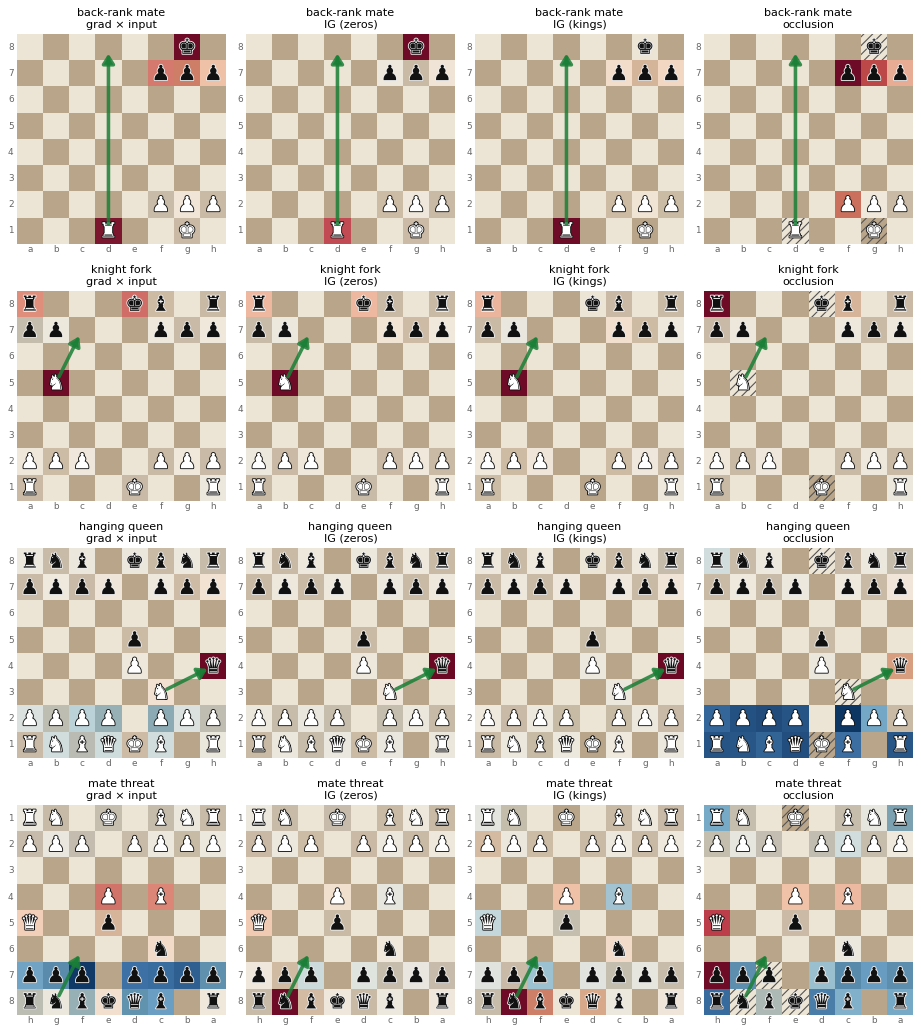

In [11]:
def all_methods(model, board, target):
    xb = board_tensor(board)
    return {
        "grad × input": square_map(grad_x_input(target, xb), board.turn),
        "IG (zeros)":   square_map(integrated_gradients(target, xb, torch.zeros_like(xb)), board.turn),
        "IG (kings)":   square_map(integrated_gradients(target, xb, kings_only_baseline(xb)), board.turn),
        "occlusion":    occlusion(target, board),
    }

panels = []
for name, b in SHOWCASE.items():
    move = top_moves(engine, b, 1)[0][0][0]
    for method, m in all_methods(engine, b, policy_target(engine, b, move)).items():
        panels.append(dict(board=b, values=m, move=move, hatch=hatched(b, m) if method == "occlusion" else (),
                           title=f"{name}\n{method}"))
show_boards(panels, ncols=4, size=2.9);

The three gradient methods agree on the **actors**: the knight that forks, the
rook that mates. Occlusion can't score those, because the moving piece can't be
removed (hatched). Where the methods differ is the **conditions**.

* **Back-rank mate.** IG (zeros) gives almost everything to the black king and
  the rook. Grad × input, IG (kings) and occlusion all give the f7/g7/h7 pawns
  real credit. Occlusion gives them the most.
* **Knight fork.** The gradient methods put the knight first, with the a8 rook
  (and, except for IG (kings), the e8 king) next. Occlusion's strongest square
  is the **rook on a8**, the piece that gets won. It can't score the king.
* **Hanging queen.** The three gradient methods put the black queen first.
  Grad × input also gives every White piece a negative score, like the
  occlusion interaction effect from section 7. Neither IG map shows that.
* **Mate threat.** Only the two IG maps agree, on the **g8 knight** (the piece
  that moves). Grad × input blames every Black pawn, and occlusion tells a third
  story. When the methods scatter like this, no single piece explains the
  choice.

They answer different questions, and none of them is "the" explanation.
**Gradient methods ask what a smooth path from the baseline passes through.
Occlusion asks what is necessary *one piece at a time*.** Occlusion also has a
blind spot: if two pieces each guard the same square, removing either one
changes nothing, so neither gets credit.

## 9 · Explaining a blunder (contrastive attribution)

In the mate-threat position the network prefers ...Nf6, which loses to Qxf7#,
over ...g6, which defends. The question worth asking is **"why Nf6 *rather than*
g6?"** That question is its own scalar:

$$f(x) = \log \pi(\text{Nf6}\mid x) - \log \pi(\text{g6}\mid x)$$

This is a **contrastive** target. Anything that helps both moves equally
cancels out, and what remains is the evidence that separated them. It is how
people actually ask about decisions ("why not the other one?"), and it also
removes the legal-move renormalisation problem from section 7.

π(Nf6) = 15.8%, π(g6) = 6.2%, contrast = +0.93


after ...Nf6: White's value -0.19; White's top moves: Qf5 26%, Qg5 19%, Qf3 19%
after ...g6: White's value +0.08; White's top moves: Qe2 29%, Qf3 24%, Qd1 18%
after ...Nf6, the network gives the mating Qxf7# only 0.2%
engine with 200-sim search, as Black: Nf6
engine with 200-sim search, as White after ...Nf6: Qg5


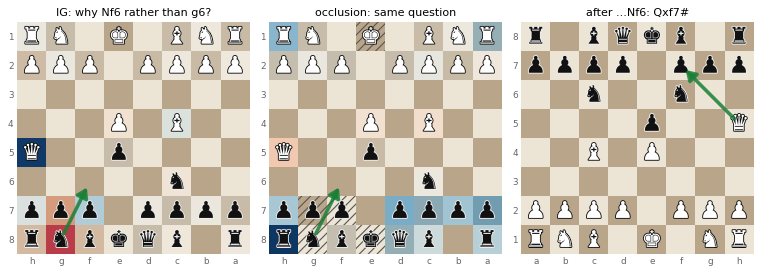

In [12]:
b = SHOWCASE["mate threat"]; xb = board_tensor(b)
nf6, g6 = chess.Move.from_uci("g8f6"), chess.Move.from_uci("g7g6")
p_nf6, p_g6 = policy_target(engine, b, nf6), policy_target(engine, b, g6)

def contrast_for(board):
    a_, b_ = p_nf6.for_board(board), p_g6.for_board(board)
    if a_ is None or b_ is None:
        return None
    return Target("log π(Nf6) − log π(g6)", lambda x: a_(x) - b_(x), contrast_for)
contrast = contrast_for(b)

with torch.no_grad():
    print(f"π(Nf6) = {p_nf6(xb).exp().item():.1%}, π(g6) = {p_g6(xb).exp().item():.1%}, "
          f"contrast = {contrast(xb).item():+.2f}")
ig_c = square_map(integrated_gradients(contrast, xb, kings_only_baseline(xb)), b.turn)
occ_c = occlusion(contrast, b)

# what does the network think of the position *after* each move?
after = {}
for mv in [nf6, g6]:
    b2 = b.copy(); b2.push(mv)
    moves, wdl = top_moves(engine, b2, 3)
    after[b.san(mv)] = (b2, moves, wdl)
    print(f"after ...{b.san(mv)}: White's value {wdl[0]-wdl[2]:+.2f}; White's top moves: "
          + ", ".join(f"{b2.san(m)} {p:.0%}" for m, p in moves))
b2 = after["Nf6"][0]
qxf7 = policy_target(engine, b2, chess.Move.from_uci("h5f7"))
with torch.no_grad():
    print(f"after ...Nf6, the network gives the mating Qxf7# only {qxf7(board_tensor(b2)).exp().item():.1%}")

# and with search: the full engine (network + 200 MCTS simulations, as in the browser)
from chesslib.arena import MCTSPlayer
print(f"engine with 200-sim search, as Black: {b.san(MCTSPlayer(engine, sims=200).move(b.copy()))}")
print(f"engine with 200-sim search, as White after ...Nf6: {b2.san(MCTSPlayer(engine, sims=200).move(b2.copy()))}")

show_boards([dict(board=b, values=ig_c, move=nf6, title="IG: why Nf6 rather than g6?"),
             dict(board=b, values=occ_c, move=nf6, hatch=hatched(b, occ_c), title="occlusion: same question"),
             dict(board=b2, move=chess.Move.from_uci("h5f7"), title="after ...Nf6: Qxf7#")], ncols=3, size=3.2);

**First finding: a blind spot.** The network doesn't just miss the threat.
After ...Nf6 it gives the mating Qxf7# 0.2%, and its value says White is
*worse* off after ...Nf6 (−0.19) than after ...g6 (+0.08). So neither head has
a "queen and bishop against f7" pattern. This also explains why search doesn't
help. With 200 simulations the engine still plays ...Nf6, and as White it
misses the mate in one. MCTS only explores moves the policy gives some prior
to, and at 0.2% it never tries Qxf7. A plausible cause is the training
data: in the 6,000 `ab2` games, only 3 end in mate on f7/f2 within the first 20
plies.

**Second finding: where does the queen fit?** IG's strongest square is the
**queen on h5**, in blue: the queen pushes the network *towards* g6. So the
network does register the queen. But ...g6 also *attacks* the queen, so is the
queen's pull "defend f7" or "kick the queen"? Attribution can't tell us. It says
**where** the network looks, not **what it computes** there.

Occlusion disagrees. It gives the queen a *positive* score (+0.7): removing
the queen makes Nf6 *less* preferred. Its biggest effects are on pieces far
from the action: the h8 rook and the queenside pawns. That looks like the
interaction effect from section 7 again. When two methods disagree this much,
neither story should be believed without more evidence.

## 10 · Are the explanations faithful? Deletion curves

So far we have judged maps by eye, checking whether they match what a chess
player would say. That measures **plausibility**. **Faithfulness** asks
something else: *does the map describe what the network actually does?* The two
can come apart: a map can look sensible and be wrong about the model, or look
odd and be right.

A standard faithfulness test is the **deletion curve**. Remove input features
in the order the method ranks them, most important first. If the ranking is
faithful, the output should fall fast. Pieces make this a natural test for
chess. For 300 positions from real games we:

1. compute each method's attribution for the **value** (no legal-move softmax to
   confuse things);
2. remove pieces one at a time, most positive attribution first, skipping any
   removal that would make the position illegal;
3. record how far the value falls.

We compare against two reference orders. **Random** is the floor: a method
that doesn't beat it carries no information. **Material** removes our most
valuable piece first (queen, then rooks, …). It is the "no network needed"
chess answer, and a method that can't beat it hasn't told us anything a beginner
didn't know.

300 positions × 6 methods × 2 tests in 86s


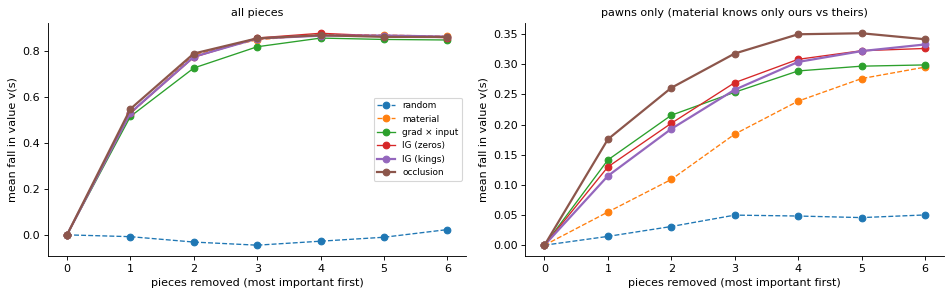

area under the curve (mean fall in value over k = 1..6)
                 all pieces  pawns only
  random             -0.017       0.040
  material            0.792       0.193
  grad × input        0.767       0.249
  IG (zeros)          0.792       0.260
  IG (kings)          0.791       0.254
  occlusion           0.795       0.299


In [13]:
VALUES = {chess.PAWN: 1, chess.KNIGHT: 3, chess.BISHOP: 3, chess.ROOK: 5, chess.QUEEN: 9}
K = 6

def rank_by_value_attribution(model, board, method, rng, pawns_only=False):
    t = value_target(model); xb = board_tensor(board)
    cands = removable_squares(board)
    if pawns_only:
        cands = [sq for sq in cands if board.piece_at(sq).piece_type == chess.PAWN]
    if method == "random":
        return list(rng.permutation(cands))
    if method == "material":   # our pieces, biggest first; then theirs, smallest first
        def key(sq):
            p = board.piece_at(sq)
            return (0, -VALUES[p.piece_type]) if p.color == board.turn else (1, VALUES[p.piece_type])
        return sorted(cands, key=key)
    if method == "occlusion":
        m = occlusion(t, board)
    elif method == "grad × input":
        m = square_map(grad_x_input(t, xb), board.turn)
    elif method == "IG (kings)":
        m = square_map(integrated_gradients(t, xb, kings_only_baseline(xb), steps=32), board.turn)
    elif method == "IG (zeros)":
        m = square_map(integrated_gradients(t, xb, torch.zeros_like(xb), steps=32), board.turn)
    return sorted(cands, key=lambda sq: -m[sq])

@torch.no_grad()
def deletion_curve(model, board, order, k=K):
    t = value_target(model); cur = board; removed = []
    out = [t(board_tensor(board)).item()]
    for sq in order:
        if len(out) > k:
            break
        nxt = remove_pieces(board, removed + [sq])
        if nxt.was_into_check():   # illegal position: skip this piece
            continue
        removed.append(sq); out.append(t(board_tensor(nxt)).item())
    out += [out[-1]] * (k + 1 - len(out))
    return np.array(out)

METHODS = ["random", "material", "grad × input", "IG (zeros)", "IG (kings)", "occlusion"]
t0 = time.time()
curves = {}
for pawns_only in (False, True):
    rng = np.random.default_rng(0)
    curves[pawns_only] = {m: np.array([deletion_curve(engine, b, rank_by_value_attribution(engine, b, m, rng, pawns_only))
                                       for b in positions]) for m in METHODS}
print(f"{len(positions)} positions × {len(METHODS)} methods × 2 tests in {time.time()-t0:.0f}s")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, pawns_only in zip(axes, (False, True)):
    for m in METHODS:
        drop = curves[pawns_only][m][:, 0:1] - curves[pawns_only][m]     # how far the value has fallen
        ax.plot(range(K + 1), drop.mean(0), marker="o", label=m,
                lw=2 if m in ("IG (kings)", "occlusion") else 1.2, ls="--" if m in ("random", "material") else "-")
    ax.set_xlabel("pieces removed (most important first)"); ax.set_ylabel("mean fall in value v(s)")
    ax.set_title("pawns only (material knows only ours vs theirs)" if pawns_only else "all pieces", fontsize=10)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

print("area under the curve (mean fall in value over k = 1..6)")
print(f"  {'':13s} {'all pieces':>11s} {'pawns only':>11s}")
for m in METHODS:
    auc = [(curves[p][m][:, :1] - curves[p][m])[:, 1:].mean() for p in (False, True)]
    print(f"  {m:13s} {auc[0]:11.3f} {auc[1]:11.3f}")

**All pieces (left).** Every method beats random by a wide margin. But
**material matches all of them.** Removing our queen first is about as good as
anything an attribution method suggests. For this network's value, "which piece
matters most?" is mostly answered by material, and the test has no room to
show anything more.

**Pawns only (right).** Every pawn is worth 1, so material can only say "remove
our pawns before theirs." That is still far better than random, because
removing their pawns *raises* our value. The attribution methods beat it
clearly. At the first removal, occlusion's pick drops the value about three
times as much as material's, and IG and grad × input about two to two and a
half times as much. That lead is information about **this
network**, about which pawns it thinks matter, that piece values alone couldn't
supply.

Two more lessons from this experiment:

* **Design the test so the trivial answer can't win.** Otherwise a faithfulness
  score mostly measures the test, not the method.
* **Watch for circularity.** Occlusion's first pick is the single removal it
  has already measured, so a deletion test is partly built in its favour. Any
  faithfulness metric favours the methods whose question matches its own.

## 11 · Sanity check: does the explanation depend on the model at all?

Adebayo et al. (2018) proposed a test that a number of popular image-saliency
methods *failed*. **Re-initialise the network's weights, layer by layer from the
output down, and recompute the explanation.** An explanation of what the network
*learned* has to change once the learned weights are gone. If it doesn't, it was
showing us the input (edges, textures), not the model.

This is a real risk here. Grad × input and IG (kings) are zero on every empty
square, and occlusion only scores pieces, so
**any** network, even a random one, gives a map that is non-zero exactly on the
pieces. That looks like "the network is looking at the pieces," for free. So we
compare maps **only on occupied squares**, using rank correlation, and track how
the correlation with the trained network's map falls as more layers are
randomised.

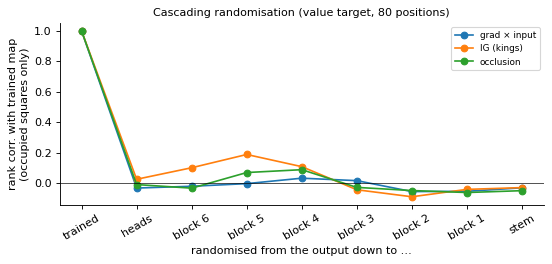

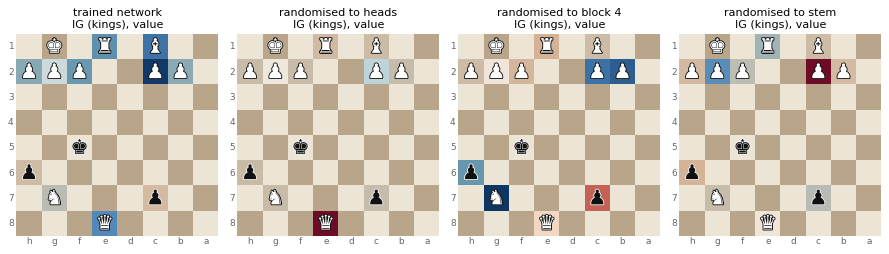

In [14]:
stages = list(randomization_stages(engine))      # heads, block 6, ..., block 1, stem
sub = positions[:80]

def value_maps(model, board):
    t, xb = value_target(model), board_tensor(board)
    return {"grad × input": square_map(grad_x_input(t, xb), board.turn),
            "IG (kings)": square_map(integrated_gradients(t, xb, kings_only_baseline(xb), steps=32), board.turn),
            "occlusion": occlusion(t, board)}

def pieces_of(board):  # non-king pieces: the squares every method scores
    return [sq for sq, p in board.piece_map().items() if p.piece_type != chess.KING]

trained = [value_maps(engine, b) for b in sub]
corr = {m: [] for m in trained[0]}
example = {}
for stage in stages:
    net = recalibrate_batchnorm(randomized_copy(engine, stage, seed=1), X)
    maps = [value_maps(net, b) for b in sub]
    for m in corr:
        rs = []
        for b, tm, rm in zip(sub, trained, maps):
            sq = [s for s in pieces_of(b) if np.isfinite(tm[m][s]) and np.isfinite(rm[m][s])]
            rs.append(rank_corr(tm[m][sq], rm[m][sq]))
        corr[m].append(np.nanmean(rs))
    example[stage] = maps[3]

fig, ax = plt.subplots(figsize=(7, 3.4))
for m, c in corr.items():
    ax.plot(["trained"] + stages, [1.0] + c, "o-", label=m)
ax.axhline(0, color="k", lw=0.6)
ax.set_ylabel("rank corr. with trained map\n(occupied squares only)")
ax.set_xlabel("randomised from the output down to …")
ax.set_title("Cascading randomisation (value target, 80 positions)", fontsize=10)
ax.legend(fontsize=8); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

b = sub[3]
show_boards([dict(board=b, values=trained[3]["IG (kings)"], title="trained network\nIG (kings), value")]
            + [dict(board=b, values=example[s]["IG (kings)"], title=f"randomised to {s}\nIG (kings), value")
               for s in ["heads", "block 4", "stem"]], ncols=4, size=2.8);

All three methods **pass**. Once the value head alone is re-initialised, the
correlation with the trained map falls close to zero (it never gets above 0.2),
and the maps of the randomised networks look nothing like the trained one. For
example, the black queen on e8 changes sign, from negative to the strongest
positive. These
explanations describe learned weights, not just where the pieces are.

So why bring it up? The random maps **still highlight pieces**, and to someone
seeing one map in isolation they would look plausible. Run this check before
believing any saliency method, especially on a new architecture. It costs one
loop.

## 12 · Summary

| method | the question it answers | cost | watch out for |
|---|---|---|---|
| gradient | what if a *tiny* bit of X appeared here? | 1 backward | hypothetical; meaningless for 0/1 inputs |
| grad × input | first-order share of each present feature | 1 backward | doesn't add up; nonzero only where the input is |
| integrated gradients | share of $f(x) - f(x')$ along a path from a baseline | ~64 backward | **the baseline is half the question**; the path goes through impossible boards |
| occlusion | what changes if this one piece is removed? | 1 forward per piece | changes the legal moves; can't see interactions between pieces |
| contrastive target | why A *rather than* B? | as the method | (a target, not a method: use with any of the above) |

**What we learned about this network**
* For single decisions, it attends to the pieces a chess player would name:
  the forking knight and the rook it wins, the mating rook and the pawns that
  box in the king.
* It has **blind spots that attribution helped find**:
  * the Qxf7# pattern is missing from both its policy and its value, so even
    200 simulations of search don't find it;
  * in the hanging-queen position, its value head treats a lost queen as worth
    less than a rook.
* Its value is mostly material, judging by the deletion curves. Among pawns,
  where material can't decide, it still ranks some above others.

**What we learned about attribution**
* Every method answers a slightly different question, and the choices of
  target and baseline matter as much as the choice of method.
* Plausible ≠ faithful. Deletion curves test faithfulness to the model, and
  randomisation checks test that the model matters at all. A faithful map of a
  wrong model still looks wrong (the hanging queen).
* Attribution says **where** the network looks. It can't say **what it
  computes** there. "The knight on b5 matters" doesn't tell us whether the
  network *represents* "this knight forks the king and rook." That is the
  question for **notebook 2: probing**.